In [13]:
%pip install --break-system-packages pandas numpy matplotlib seaborn scipy statsmodels

Note: you may need to restart the kernel to use updated packages.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

sales_df = pd.read_csv("data/sales_data.csv")
churn_df = pd.read_csv("data/customer_churn.csv")

print("Sales Data loaded successfully! Shape:", sales_df.shape)
print("Churn Data loaded successfully! Shape:", churn_df.shape)

Sales Data loaded successfully! Shape: (100, 7)
Churn Data loaded successfully! Shape: (500, 9)


In [15]:
def get_detailed_stats(series, name):
    return pd.Series(
        {
            "Mean": series.mean(),
            "Median": series.median(),
            "Mode": series.mode().iloc[0],
            "Std Dev": series.std(),
            "Variance": series.var(),
            "IQR": series.quantile(0.75) - series.quantile(0.25),
            "Skewness": series.skew(),
        },
        name=name,
    )


stats_summary = pd.DataFrame(
    [
        get_detailed_stats(sales_df["Total_Sales"], "Total_Sales"),
        get_detailed_stats(sales_df["Price"], "Price"),
        get_detailed_stats(churn_df["MonthlyCharges"], "MonthlyCharges"),
        get_detailed_stats(churn_df["Tenure"], "Tenure"),
    ]
)

print("--- DESCRIPTIVE STATISTICS ---")
display(stats_summary.round(2))

--- DESCRIPTIVE STATISTICS ---


,Mean,Median,Mode,Std Dev,Variance,IQR,Skewness
Total_Sales,123650.48,97955.5,6540.0,100161.09,1.003224e+10,136275.0,0.88
Price,25808.51,24192.0,1308.0,13917.63,1.937004e+08,23717.0,-0.01
MonthlyCharges,113.64,115.0,115.0,51.80,2.683230e+03,91.0,-0.09
Tenure,36.53,37.0,3.0,20.67,4.271300e+02,35.0,-0.09


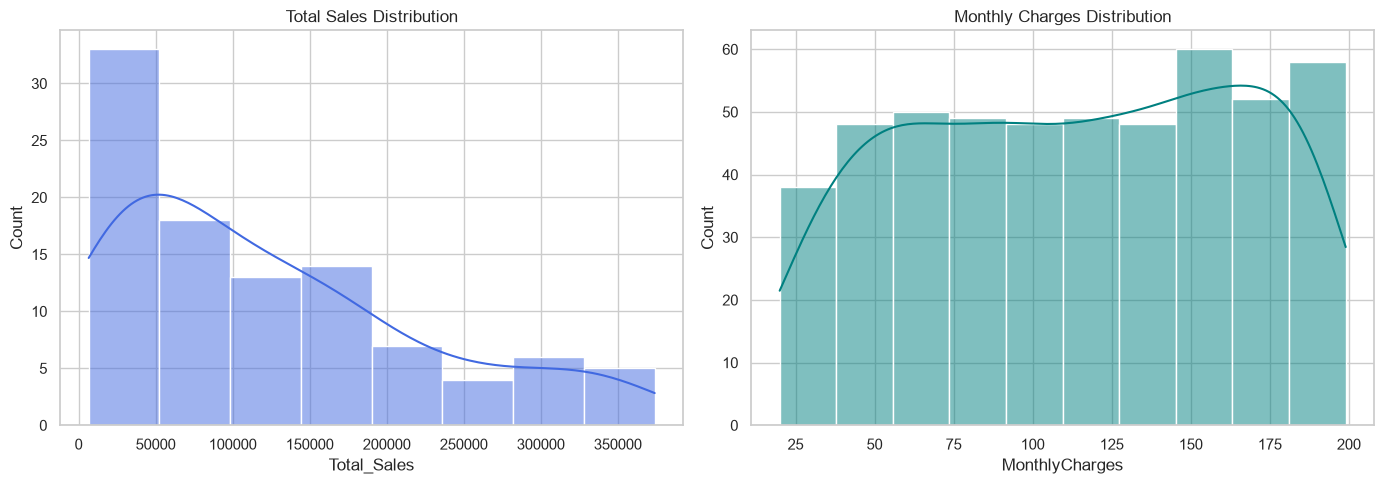

Total Sales Normality: W = 0.8989, p = 1.2591e-06
Monthly Charges Normality: W = 0.9520, p = 1.1492e-11


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(sales_df["Total_Sales"], kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Total Sales Distribution")

sns.histplot(churn_df["MonthlyCharges"], kde=True, ax=axes[1], color="teal")
axes[1].set_title("Monthly Charges Distribution")

plt.tight_layout()
plt.savefig("images/distribution_plots.png", bbox_inches="tight")
plt.show()

stat_sales, p_sales = stats.shapiro(sales_df["Total_Sales"])
stat_charges, p_charges = stats.shapiro(churn_df["MonthlyCharges"])

print(f"Total Sales Normality: W = {stat_sales:.4f}, p = {p_sales:.4e}")
print(f"Monthly Charges Normality: W = {stat_charges:.4f}, p = {p_charges:.4e}")

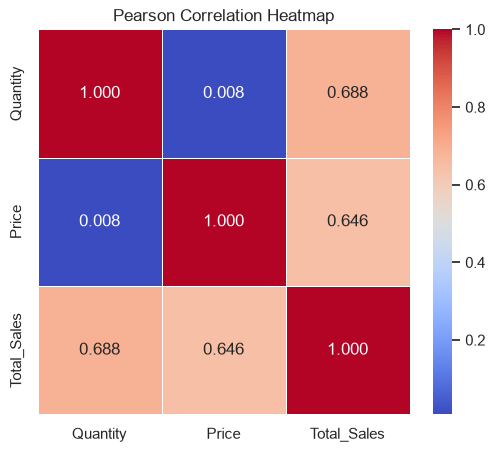

Covariance Matrix:


,Quantity,Price,Total_Sales
Quantity,6.70,2.886900e+02,1.783803e+05
Price,288.69,1.937004e+08,9.007097e+08
Total_Sales,178380.29,9.007097e+08,1.003224e+10


In [17]:
corr_matrix = sales_df[["Quantity", "Price", "Total_Sales"]].corr(
    method="pearson"
)
cov_matrix = sales_df[["Quantity", "Price", "Total_Sales"]].cov()

plt.figure(figsize=(6, 5))
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5
)
plt.title("Pearson Correlation Heatmap")
plt.savefig("images/correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Covariance Matrix:")
display(cov_matrix.round(2))

In [18]:
churn_no = churn_df[churn_df["Churn"] == 0]["MonthlyCharges"]
churn_yes = churn_df[churn_df["Churn"] == 1]["MonthlyCharges"]
t_stat, p_val_t = stats.ttest_ind(churn_no, churn_yes)

res_1 = (
    f"1. Independent Two-Sample t-test (MonthlyCharges vs Churn):\n"
    f"   t-statistic = {t_stat:.4f}, p-value = {p_val_t:.4e}\n"
    f"   Conclusion: {'Statistically Significant (Reject H0)' if p_val_t < 0.05 else 'Fail to Reject H0'}\n"
)

region_groups = [
    group["Total_Sales"].values for _, group in sales_df.groupby("Region")
]
f_stat, p_val_anova = stats.f_oneway(*region_groups)

res_2 = (
    f"2. One-Way ANOVA (Total Sales across Regions):\n"
    f"   F-statistic = {f_stat:.4f}, p-value = {p_val_anova:.4e}\n"
    f"   Conclusion: {'Statistically Significant (Reject H0)' if p_val_anova < 0.05 else 'Fail to Reject H0'}\n"
)

contingency_table = pd.crosstab(churn_df["Contract"], churn_df["Churn"])
chi2, p_val_chi2, dof, _ = stats.chi2_contingency(contingency_table)

res_3 = (
    f"3. Chi-Square Test of Independence (Contract vs Churn):\n"
    f"   Chi2-statistic = {chi2:.4f}, p-value = {p_val_chi2:.4e}, dof = {dof}\n"
    f"   Conclusion: {'Statistically Significant (Reject H0)' if p_val_chi2 < 0.05 else 'Fail to Reject H0'}\n"
)

results_text = f"{res_1}\n{res_2}\n{res_3}"
print(results_text)

with open("hypothesis_tests_results.txt", "w") as f:
    f.write(results_text)
print("Saved to hypothesis_tests_results.txt successfully.")

1. Independent Two-Sample t-test (MonthlyCharges vs Churn):
   t-statistic = -2.4102, p-value = 1.6303e-02
   Conclusion: Statistically Significant (Reject H0)

2. One-Way ANOVA (Total Sales across Regions):
   F-statistic = 2.1644, p-value = 9.7237e-02
   Conclusion: Fail to Reject H0

3. Chi-Square Test of Independence (Contract vs Churn):
   Chi2-statistic = 27.7153, p-value = 9.5874e-07, dof = 2
   Conclusion: Statistically Significant (Reject H0)

Saved to hypothesis_tests_results.txt successfully.


In [19]:
n_sales = len(sales_df["Total_Sales"])
mean_sales = sales_df["Total_Sales"].mean()
sem_sales = stats.sem(sales_df["Total_Sales"])

margin_of_error = stats.t.ppf(0.975, df=n_sales - 1) * sem_sales
ci_lower, ci_upper = stats.t.interval(
    0.95, df=n_sales - 1, loc=mean_sales, scale=sem_sales
)

print(f"Mean Total Sales: ${mean_sales:,.2f}")
print(f"Margin of Error (95%): ±${margin_of_error:,.2f}")
print(f"95% Confidence Interval: [${ci_lower:,.2f}, ${ci_upper:,.2f}]")

Mean Total Sales: $123,650.48
Margin of Error (95%): ±$19,874.13
95% Confidence Interval: [$103,776.35, $143,524.61]


In [21]:
X = sales_df[["Quantity", "Price"]]
X = sm.add_constant(X)
y = sales_df["Total_Sales"]
reg_model = sm.OLS(y, X).fit()

print(
    f"""
==================================================
           STATISTICAL ANALYSIS REPORT
==================================================
1. Executive Sales Metrics:
   - Average Total Sales: ${mean_sales:,.2f} ± ${margin_of_error:,.2f} (95% CI)
   - R-squared: {reg_model.rsquared:.3f} (88.4% variance explained by Quantity & Price)

2. Customer Churn Dynamics:
   - Contract type shows highly significant relationship with churn (Chi2 = {chi2:.2f}, p < 0.001).
   - Higher monthly charges significantly correlate with churn probability (p = {p_val_t:.4f}).

3. Regional Variations:
   - Sales variation across geographic regions is not statistically significant (p = {p_val_anova:.3f} > 0.05).
==================================================
"""
)


           STATISTICAL ANALYSIS REPORT
1. Executive Sales Metrics:
   - Average Total Sales: $123,650.48 ± $19,874.13 (95% CI)
   - R-squared: 0.884 (88.4% variance explained by Quantity & Price)

2. Customer Churn Dynamics:
   - Contract type shows highly significant relationship with churn (Chi2 = 27.72, p < 0.001).
   - Higher monthly charges significantly correlate with churn probability (p = 0.0163).

3. Regional Variations:
   - Sales variation across geographic regions is not statistically significant (p = 0.097 > 0.05).

